<a href="https://colab.research.google.com/github/mdd214/CDS230-Lab8/blob/main/Lab8_KNN_Example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
"""
==============================================================================
K-NEAREST NEIGHBORS (KNN) - ABALONE AGE GROUP CLASSIFICATION
==============================================================================

WHAT THIS SCRIPT DOES:
    Abalones are marine snails whose age is normally determined by
    cutting the shell open and counting growth rings under a microscope.
    That's slow and expensive! Instead, we use physical measurements
    (weight, length, diameter, etc.) to predict the abalone's age group:

        1. Young   — small, lightweight abalones
        2. Middle  — medium-sized abalones
        3. Old     — large, heavy abalones

    This is a MULTICLASS problem (3 classes instead of 2).

    We also introduce CROSS-VALIDATION, a more robust way to evaluate
    your model and find the best K.

BEFORE RUNNING THIS SCRIPT:
    Make sure you have the required libraries installed:

        pip install scikit-learn pandas matplotlib seaborn numpy

DATASET:
    Synthetic data modeled after the UCI Abalone dataset structure.
    No downloads needed — just run this script!


==============================================================================
"""

# ============================================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================================
# The scikit-learn workflow is very consistent regardless of dataset.
# Once you learn the pattern, you can apply it to almost any classification problem
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,       # Split data into train/test sets
    cross_val_score         # Cross-validation for robust evaluation
)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("=" * 60)
print("Abalone Age Group Classification")
print("=" * 60)
print()

Abalone Age Group Classification



In [2]:
# ============================================================================
# STEP 2: CREATE THE DATASET
# ============================================================================
# We create three groups of abalones with different characteristics:
#
#   Young abalones  → small, light, many are infants
#   Middle-aged     → medium size, mostly male/female adults
#   Old abalones    → large, heavy, almost no infants
#
# FEATURES EXPLAINED:
#   Sex          → 0=Male, 1=Female, 2=Infant
#                  (we encode text as numbers so the algorithm can use them)
#   Length       → longest shell measurement (in mm, normalized 0-1)
#   Diameter     → perpendicular to length (mm, normalized 0-1)
#   Height       → height of the meat inside the shell (mm, normalized 0-1)
#   Whole_Weight → total weight of the abalone (grams, normalized)
#   Shell_Weight → weight of the dried shell (grams, normalized)
# ============================================================================

np.random.seed(42)  # For reproducibility — everyone gets the same results

# ----- YOUNG abalones -----
# Small and light. 60% chance of being an infant (sex=2).
n_young = 100  # 100 samples

young = pd.DataFrame({
    # np.random.choice picks randomly from [0, 1, 2] with given probabilities
    # p=[0.2, 0.2, 0.6] means 20% male, 20% female, 60% infant
    'Sex':          np.random.choice([0, 1, 2], n_young, p=[0.2, 0.2, 0.6]),

    # Small length (mean=0.35, std=0.08)
    'Length':       np.random.normal(0.35, 0.08, n_young),

    # Small diameter
    'Diameter':     np.random.normal(0.26, 0.06, n_young),

    # Short height
    'Height':       np.random.normal(0.08, 0.02, n_young),

    # Light weight
    'Whole_Weight': np.random.normal(0.22, 0.12, n_young),

    # Light shell
    'Shell_Weight': np.random.normal(0.07, 0.03, n_young),

    # The label (what we want to predict)
    'Age_Group':    'Young'
})

# ----- MIDDLE-AGED abalones -----
# Medium-sized. Mostly adults (45% male, 45% female, 10% infant).
n_mid = 100

middle = pd.DataFrame({
    'Sex':          np.random.choice([0, 1, 2], n_mid, p=[0.45, 0.45, 0.1]),
    'Length':       np.random.normal(0.55, 0.07, n_mid),   # Larger than young
    'Diameter':     np.random.normal(0.43, 0.06, n_mid),
    'Height':       np.random.normal(0.14, 0.03, n_mid),
    'Whole_Weight': np.random.normal(0.80, 0.25, n_mid),   # Heavier
    'Shell_Weight': np.random.normal(0.23, 0.07, n_mid),
    'Age_Group':    'Middle'
})

# ----- OLD abalones -----
# Large and heavy. Almost all adults (48% male, 48% female, 4% infant).
n_old = 100

old = pd.DataFrame({
    'Sex':          np.random.choice([0, 1, 2], n_old, p=[0.48, 0.48, 0.04]),
    'Length':       np.random.normal(0.65, 0.06, n_old),   # Largest
    'Diameter':     np.random.normal(0.52, 0.05, n_old),
    'Height':       np.random.normal(0.18, 0.03, n_old),
    'Whole_Weight': np.random.normal(1.30, 0.35, n_old),   # Heaviest
    'Shell_Weight': np.random.normal(0.40, 0.10, n_old),
    'Age_Group':    'Old'
})

# Combine all three groups into one DataFrame
df = pd.concat([young, middle, old], ignore_index=True)

# Quick look at the data
print("STEP 2: Dataset Overview")
print("-" * 40)
print(f"Total samples:       {df.shape[0]}")        # 300
print(f"Number of features:  {df.shape[1] - 1}")    # 6 (excluding Age_Group)
print(f"Number of classes:   {df['Age_Group'].nunique()}")  # 3
print()

# Show how many of each age group we have
print("Class distribution:")
print(df['Age_Group'].value_counts().to_string())
#   Each class should have ~100 samples (balanced dataset)
print()

# Show a few sample rows
print("First 5 rows:")
print(df.head().to_string(index=False))
print()

STEP 2: Dataset Overview
----------------------------------------
Total samples:       300
Number of features:  6
Number of classes:   3

Class distribution:
Age_Group
Young     100
Middle    100
Old       100

First 5 rows:
 Sex   Length  Diameter   Height  Whole_Weight  Shell_Weight Age_Group
   1 0.356964  0.260780 0.083981      0.324678      0.087297     Young
   2 0.326079  0.347212 0.067996      0.242001      0.079338     Young
   2 0.357341  0.244121 0.081396      0.482776      0.162366     Young
   2 0.190994  0.423210 0.072294      0.123004      0.103587     Young
   0 0.332426  0.297540 0.082270      0.119233      0.066162     Young



STEP 3: Exploring the Data
----------------------------------------
Average measurements per age group:
            Sex  Length  Diameter  Height  Whole_Weight  Shell_Weight
Age_Group                                                            
Middle     0.73   0.543     0.439   0.146         0.842         0.235
Old        0.57   0.650     0.523   0.185         1.280         0.416
Young      1.26   0.350     0.262   0.082         0.215         0.066



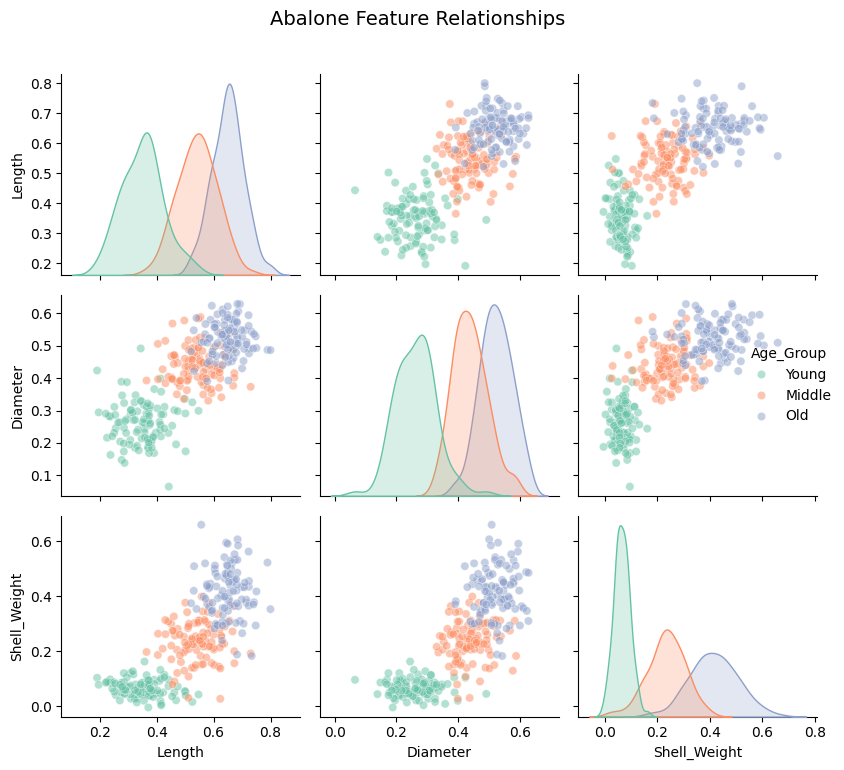

   -> Pair plot saved as 'abalone_pairplot.png'
   -> Look for features where the 3 colors separate well.
      Those features will be most useful for KNN!



/tmp/ipykernel_1484/410924374.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


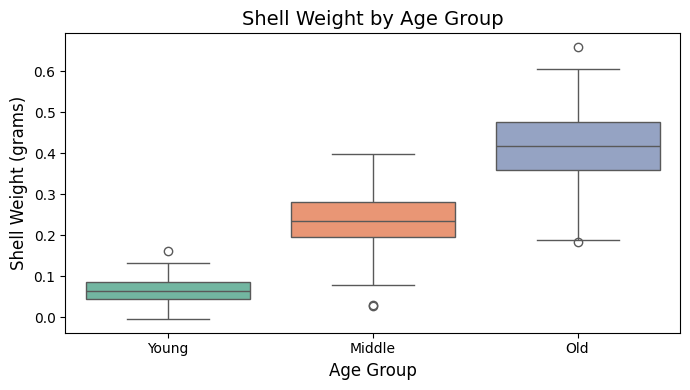

   -> Box plot saved as 'abalone_boxplot.png'



In [3]:
# ============================================================================
# STEP 3: EXPLORE THE DATA
# ============================================================================
# Let's visualize the relationships between features.
# We use a PAIR PLOT, which creates scatter plots for every
# combination of features, colored by age group.
#
# This is like getting a bird's eye view of your entire dataset.
# ============================================================================

print("STEP 3: Exploring the Data")
print("-" * 40)

# Average values for each age group
print("Average measurements per age group:")
print(df.groupby('Age_Group').mean().round(3))
print()
# Notice how values generally INCREASE from Young → Middle → Old
# This makes intuitive sense — older abalones are bigger!

# --- Pair Plot ---
# We pick 3 features + the label to keep the plot readable
# (plotting all 6 features would create 6x6=36 charts!)
plot_features = ['Length', 'Diameter', 'Shell_Weight', 'Age_Group']

sns.pairplot(
    df[plot_features],         # Only these columns
    hue='Age_Group',           # Color by age group
    palette='Set2',            # A nice color palette
    diag_kind='kde',           # Diagonal: show density curves instead of histograms
    plot_kws={                 # Settings for the scatter plots
        'alpha': 0.5,          # Semi-transparent dots
        'edgecolor': 'w'       # White edges around dots
    }
)
plt.suptitle('Abalone Feature Relationships', y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig('abalone_pairplot.png', dpi=150)
plt.show()

print("   -> Pair plot saved as 'abalone_pairplot.png'")
print("   -> Look for features where the 3 colors separate well.")
print("      Those features will be most useful for KNN!")
print()

# --- Individual feature comparison ---
# Let's also make a box plot for Shell_Weight by age group
# Box plots show the median, quartiles, and outliers
plt.figure(figsize=(7, 4))
sns.boxplot(
    data=df,
    x='Age_Group',             # Categories on x-axis
    y='Shell_Weight',          # Values on y-axis
    palette='Set2',            # Same colors as pair plot
    order=['Young', 'Middle', 'Old']  # Force this order
)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Shell Weight (grams)', fontsize=12)
plt.title('Shell Weight by Age Group', fontsize=14)
plt.tight_layout()
plt.savefig('abalone_boxplot.png', dpi=150)
plt.show()

print("   -> Box plot saved as 'abalone_boxplot.png'")
print()

In [4]:
# ============================================================================
# STEP 4: PREPARE THE DATA
# ============================================================================
# Same workflow as Example 1:
#   1. Separate features (X) from labels (y)
#   2. Split into train/test sets
#   3. Scale the features
#
# The code is nearly identical — this is the power of scikit-learn's
# consistent API design!
# ============================================================================

print("STEP 4: Preparing the Data")
print("-" * 40)

# Separate features from labels
X = df.drop('Age_Group', axis=1)    # All columns except the label
y = df['Age_Group']                 # Just the label column

# Split: 80% training, 20% testing
# stratify=y ensures each age group is proportionally represented
# in both the training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training samples: {X_train.shape[0]}")  # 240
print(f"Testing samples:  {X_test.shape[0]}")   # 60
print()

# Verify the class balance in both sets
print("Class balance check:")
print(f"  Training: {dict(y_train.value_counts())}")
print(f"  Testing:  {dict(y_test.value_counts())}")
print("  (Should be roughly proportional)")
print()

# Scale features
# Remember: fit_transform on training, transform on testing!
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # Learn + scale
X_test_scaled  = scaler.transform(X_test)         # Scale only (no learning)

print("Features scaled with StandardScaler.")
print()

STEP 4: Preparing the Data
----------------------------------------
Training samples: 240
Testing samples:  60

Class balance check:
  Training: {'Middle': np.int64(80), 'Old': np.int64(80), 'Young': np.int64(80)}
  Testing:  {'Middle': np.int64(20), 'Young': np.int64(20), 'Old': np.int64(20)}
  (Should be roughly proportional)

Features scaled with StandardScaler.



STEP 5: Training and Evaluating
----------------------------------------
Overall Accuracy: 96.67%

Classification Report:
              precision    recall  f1-score   support

      Middle       0.95      0.95      0.95        20
         Old       0.95      0.95      0.95        20
       Young       1.00      1.00      1.00        20

    accuracy                           0.97        60
   macro avg       0.97      0.97      0.97        60
weighted avg       0.97      0.97      0.97        60



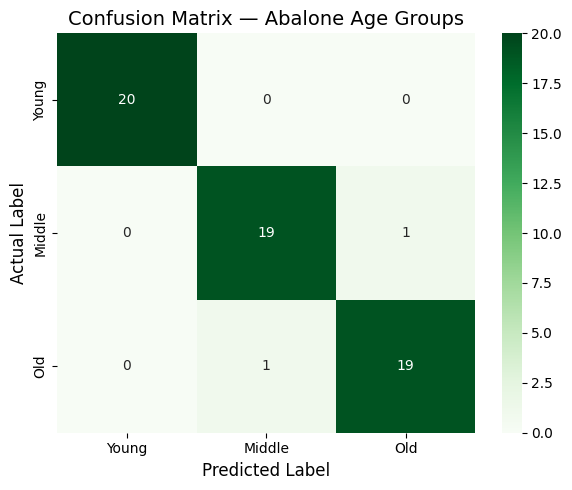

   -> Confusion matrix saved as 'abalone_confusion.png'
   -> TIP: Middle-aged abalones are often the hardest to classify
      because they overlap with both Young and Old groups.



In [5]:
# ============================================================================
# STEP 5: TRAIN AND EVALUATE THE KNN MODEL
# ============================================================================
# We start with K=7 (a reasonable starting point for 3 classes).
#
# For MULTICLASS problems, the confusion matrix becomes 3x3 instead
# of 2x2, and the classification report shows metrics for each class.
# ============================================================================

print("STEP 5: Training and Evaluating")
print("-" * 40)

# Create and train the model
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(X_train_scaled, y_train)

# Make predictions
y_pred = knn.predict(X_test_scaled)

# --- Accuracy ---
accuracy = accuracy_score(y_test, y_pred)
print(f"Overall Accuracy: {accuracy:.2%}")
print()

# --- Classification Report ---
# For multiclass problems, this shows precision/recall/f1 for EACH class
# plus macro avg (simple average) and weighted avg (accounts for class size)
print("Classification Report:")
print(classification_report(y_test, y_pred))

# --- Confusion Matrix ---
# Now it's 3x3! Diagonal = correct, off-diagonal = mistakes
# You can see exactly which age groups get confused with each other
cm = confusion_matrix(
    y_test, y_pred,
    labels=['Young', 'Middle', 'Old']  # Force this order in the matrix
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,                                    # Show numbers
    fmt='d',                                       # Integer format
    cmap='Greens',                                 # Green color scheme
    xticklabels=['Young', 'Middle', 'Old'],        # Predicted labels
    yticklabels=['Young', 'Middle', 'Old']         # Actual labels
)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.title('Confusion Matrix — Abalone Age Groups', fontsize=14)
plt.tight_layout()
plt.savefig('abalone_confusion.png', dpi=150)
plt.show()

print("   -> Confusion matrix saved as 'abalone_confusion.png'")
print("   -> TIP: Middle-aged abalones are often the hardest to classify")
print("      because they overlap with both Young and Old groups.")
print()

STEP 6: Finding the Best K with Cross-Validation
----------------------------------------
   K= 1 → CV Accuracy = 96.25% (±2.76%)
   K= 5 → CV Accuracy = 97.08% (±2.50%)
   K=10 → CV Accuracy = 97.92% (±1.86%)
   K=15 → CV Accuracy = 97.08% (±2.50%)
   K=20 → CV Accuracy = 97.08% (±2.83%)
   K=25 → CV Accuracy = 97.08% (±2.12%)
   K=30 → CV Accuracy = 96.67% (±1.67%)



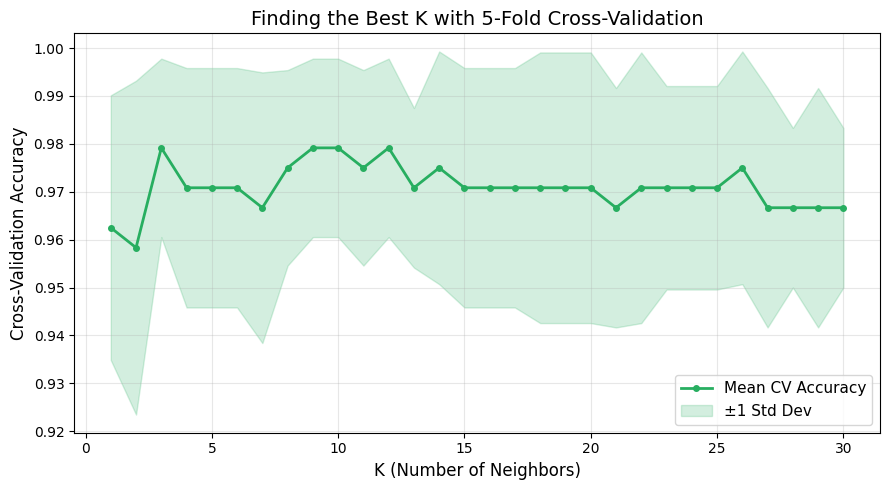

   -> Best K = 3
   -> Best CV Accuracy = 97.92%
   -> Chart saved as 'abalone_best_k.png'



In [6]:
# ============================================================================
# STEP 6: FIND THE BEST K USING CROSS-VALIDATION
# ============================================================================
#
# CROSS-VALIDATION is more reliable. Here's how 5-fold CV works:
#
#   1. Divide training data into 5 equal parts ("folds")
#   2. Train on 4 folds, test on the remaining 1 fold
#   3. Repeat 5 times, each time leaving out a different fold
#   4. Average the 5 accuracy scores
#
#   Fold 1: [TEST] [train] [train] [train] [train]  → accuracy_1
#   Fold 2: [train] [TEST] [train] [train] [train]  → accuracy_2
#   Fold 3: [train] [train] [TEST] [train] [train]  → accuracy_3
#   Fold 4: [train] [train] [train] [TEST] [train]  → accuracy_4
#   Fold 5: [train] [train] [train] [train] [TEST]  → accuracy_5
#
#   Final score = average of accuracy_1 through accuracy_5
#
# This gives a much more stable estimate of model performance!
# ============================================================================

print("STEP 6: Finding the Best K with Cross-Validation")
print("-" * 40)

# Test K from 1 to 30
k_range = range(1, 31)

# For each K, we'll store:
#   - The mean CV accuracy (average across 5 folds)
#   - The std of CV accuracy (how much it varies between folds)
cv_means = []    # Average accuracy
cv_stds = []     # Standard deviation (spread)

for k in k_range:
    # Create a model with this K
    model = KNeighborsClassifier(n_neighbors=k)

    # Run 5-fold cross-validation on the TRAINING data only
    # cross_val_score returns an array of 5 accuracy scores
    scores = cross_val_score(
        model,                   # The model to evaluate
        X_train_scaled,          # The training features (scaled)
        y_train,                 # The training labels
        cv=5,                    # 5 folds
        scoring='accuracy'       # Metric to use
    )

    # Store the mean and standard deviation
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())

    # Print progress every 5 steps
    if k % 5 == 0 or k == 1:
        print(f"   K={k:2d} → CV Accuracy = {scores.mean():.2%} (±{scores.std():.2%})")

print()

# --- Plot the results ---
# We plot the mean accuracy as a line and add a shaded region
# showing ± 1 standard deviation (the uncertainty band)
plt.figure(figsize=(9, 5))

# Convert to numpy arrays for easy math
cv_means = np.array(cv_means)
cv_stds = np.array(cv_stds)
k_list = list(k_range)

# Main line (mean accuracy)
plt.plot(k_list, cv_means, marker='o', color='#27ae60',
         linewidth=2, markersize=4, label='Mean CV Accuracy')

# Shaded region (±1 standard deviation)
# This shows the UNCERTAINTY in our accuracy estimate
plt.fill_between(
    k_list,
    cv_means - cv_stds,     # Lower bound
    cv_means + cv_stds,     # Upper bound
    alpha=0.2,              # Transparency
    color='#27ae60',        # Same green
    label='±1 Std Dev'
)

plt.xlabel('K (Number of Neighbors)', fontsize=12)
plt.ylabel('Cross-Validation Accuracy', fontsize=12)
plt.title('Finding the Best K with 5-Fold Cross-Validation', fontsize=14)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('abalone_best_k.png', dpi=150)
plt.show()

# Find the best K
best_k = k_list[np.argmax(cv_means)]
best_cv_accuracy = cv_means.max()

print(f"   -> Best K = {best_k}")
print(f"   -> Best CV Accuracy = {best_cv_accuracy:.2%}")
print(f"   -> Chart saved as 'abalone_best_k.png'")
print()

In [7]:
# ============================================================================
# STEP 7: RETRAIN WITH BEST K AND EVALUATE ON TEST SET
# ============================================================================
# Now we retrain using the best K we found, and evaluate on the
# held-out test set one final time.
#
# This is the TRUE performance estimate — cross-validation helped
# us choose K, and now we see how well that choice works on
# completely unseen data.
# ============================================================================

print("STEP 7: Final Evaluation with Best K")
print("-" * 40)

# Retrain with the best K
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train_scaled, y_train)

# Final predictions on the test set
y_pred_final = final_model.predict(X_test_scaled)

# Final accuracy
final_accuracy = accuracy_score(y_test, y_pred_final)
print(f"Final Test Accuracy (K={best_k}): {final_accuracy:.2%}")
print()

# Final classification report
print("Final Classification Report:")
print(classification_report(y_test, y_pred_final))

STEP 7: Final Evaluation with Best K
----------------------------------------
Final Test Accuracy (K=3): 98.33%

Final Classification Report:
              precision    recall  f1-score   support

      Middle       0.95      1.00      0.98        20
         Old       1.00      0.95      0.97        20
       Young       1.00      1.00      1.00        20

    accuracy                           0.98        60
   macro avg       0.98      0.98      0.98        60
weighted avg       0.98      0.98      0.98        60



In [8]:
# ============================================================================
# STEP 8: PREDICT ON BRAND NEW DATA
# ============================================================================
# Let's classify three new abalones we've never seen before.
# We'll see how confident the model is about each prediction.
#
# predict_proba() tells us the fraction of K neighbors in each class.
# For example, if K=7 and 5 out of 7 neighbors are "Old",
# then the probability for "Old" = 5/7 ≈ 71.4%
# ============================================================================

print("STEP 8: Predicting New Abalones")
print("-" * 40)

# Three new abalones with different characteristics
new_abalones = pd.DataFrame({
    'Sex':          [2,    1,    0],       # Infant, Female, Male
    'Length':       [0.30, 0.58, 0.68],   # Small, Medium, Large
    'Diameter':     [0.22, 0.45, 0.55],
    'Height':       [0.07, 0.15, 0.19],
    'Whole_Weight': [0.15, 0.85, 1.40],
    'Shell_Weight': [0.05, 0.25, 0.42],
})

print("New abalone measurements:")
print(new_abalones.to_string(index=False))
print()

# IMPORTANT: Scale using the SAME scaler fit on training data
# (Never create a new StandardScaler for new data!)
new_scaled = scaler.transform(new_abalones)

# Get predictions and probabilities
predictions = final_model.predict(new_scaled)
probabilities = final_model.predict_proba(new_scaled)

# Display results for each abalone
class_labels = final_model.classes_  # ['Middle', 'Old', 'Young'] (alphabetical)

for i in range(len(new_abalones)):
    print(f"Abalone #{i+1}:")
    print(f"   Predicted age group: {predictions[i]}")
    print(f"   Confidence breakdown:")

    for cls, prob in zip(class_labels, probabilities[i]):
        # Visual bar to make probabilities easy to read
        bar_length = int(prob * 25)
        bar = '█' * bar_length + '░' * (25 - bar_length)
        print(f"      {cls:8s} {bar} {prob:6.1%}")
    print()

print()

STEP 8: Predicting New Abalones
----------------------------------------
New abalone measurements:
 Sex  Length  Diameter  Height  Whole_Weight  Shell_Weight
   2    0.30      0.22    0.07          0.15          0.05
   1    0.58      0.45    0.15          0.85          0.25
   0    0.68      0.55    0.19          1.40          0.42

Abalone #1:
   Predicted age group: Young
   Confidence breakdown:
      Middle   ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Old      ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Young    █████████████████████████ 100.0%

Abalone #2:
   Predicted age group: Middle
   Confidence breakdown:
      Middle   █████████████████████████ 100.0%
      Old      ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Young    ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%

Abalone #3:
   Predicted age group: Old
   Confidence breakdown:
      Middle   ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Old      █████████████████████████ 100.0%
      Young    ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%


